## Библиотеки для построения графиков и интерактивного интерфейса

### Matplotlib

Самая популярная и базовая библиотека для построения графиков - это matplotlib. Это огромная библиотека, и изучать ее возможности можно неделями, но на самом деле главное - разобраться в основных ее понятиях, остальное - уже финтифлюшки. Matplotlib необходимо отдельно устанавливать:

    pip install matplotlib
    
(в Гугл колабе уже установлен).

После установки matplotlib надо импортировать. Это стандартно делается так:

In [ ]:
import matplotlib.pyplot as plt

**Архитектура Matplotlib**

Matplotlib имеет три основных слоя: слой нижнего уровня (backend), слой рисунков и слой скриптов.

Слой нижнего уровня содержит три интерфейсных класса: канва рисунка (figure canvas), определяющая область рисунка, прорисовщик (renderer), умеющий рисовать на этой канве, и событие (event), обрабатывающее ввод пользователя вроде щелчков мыши.

Слой скриптов – это облегченный интерфейс, который очень полезен для ежедневного применения.  

Слой рисунков знает, как рисовать с помощью Renderer'а и рисовать на канве. Все, что находится на рисунке Matplotlib, является экземпляром слоя рисунка (artist). Засечки, заголовок, метки – все это индивидуальные объекты слоя рисунков.

События нужны для интерактива.

Два класса объектов, о которых необходимо знать для работы с графиками - это Figure и Axes.

**Figure** - это контейнер самого верхнего уровня, та область, на которой все нарисовано. Таких областей может быть несколько, каждая из которых может содержать несколько контейнеров Axes.

**Axes** - это та область на которой чаще всего и отражаются графики (данные в виде графиков), а также все вспомогательные атрибуты (линии сетки, метки, указатели и т.д.).
Каждая область Axes содержит XAxis и YAxis. Они содержат, деления, метки и прочие вспомогательные атрибуты.

Когда собираемся нарисовать график, сперва заводим экземпляр класса Figure, а потом к нему специальным методом добавляем область для будущего графика.

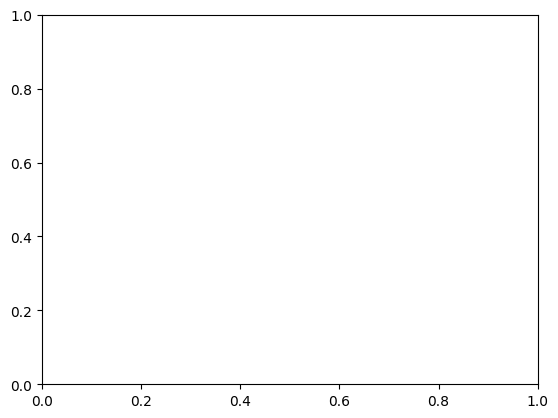

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)

plt.show()

Можно убедиться, что эти фигуры разные, если поменять их цвет:

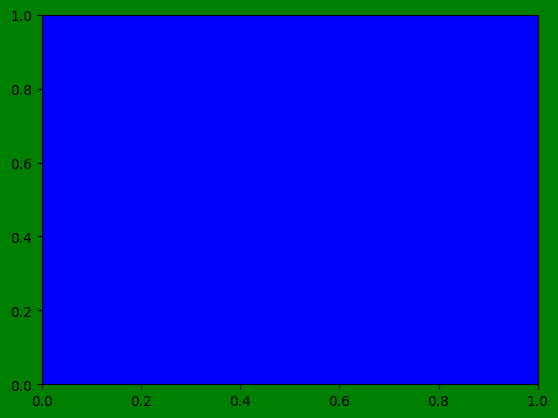

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
fig.set(facecolor='green')
ax.set(facecolor='blue')
plt.show()

Вообще метод set() есть и у фигуры, и у области графика, и там можно устанавливать очень много всего разного. Причем обычно есть варианты вида set(Title='...') vs set_title().

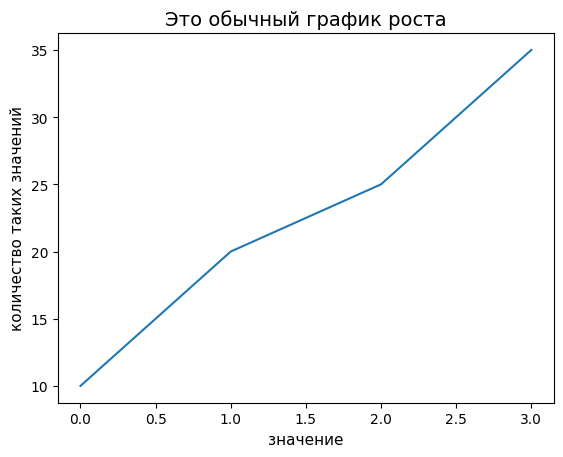

In [62]:
Y = [10, 20, 25, 35]

fig = plt.figure()
ax = fig.add_subplot(111)

ax.plot(Y)

ax.set_title('Это обычный график роста', fontsize=14)
ax.set_xlabel(u'значение', fontsize=11)
ax.set_ylabel(u'количество таких значений', fontsize=11)

plt.show()

Обратите внимание, что в Colab весь код создания и настройки графика обязательно должен находиться в одной ячейке. Каждый запуск ячейки с add_subplot() создает объект Axes заново, поэтому все методы ax.set_... должны идти следом, а в конце plt.show() для вывода результата. Если вы напишете ax = fig.add_subplot() в первой ячейке, а ax.set_title() во второй, название не отобразится, так как Colab закрывает и выводит график сразу по окончании работы первой ячейки.

Полезно знать, что вместо fig = plt.figure и ax = fig.add_subplot() можно обойтись всего одной командой:

    fig, ax = plt.subplots()

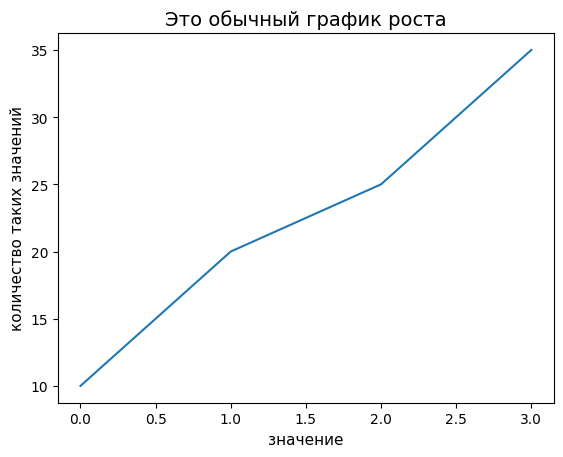

In [61]:
Y = [10, 20, 25, 35]

fig, ax = plt.subplots() # Делает то же самое, что fig = plt.figure и ax = fig.add_subplot()

ax.plot(Y)

ax.set_title('Это обычный график роста', fontsize=14)
ax.set_xlabel(u'значение', fontsize=11)
ax.set_ylabel(u'количество таких значений', fontsize=11)

plt.show()

Здесь использован график роста, созданный с помощью метода plot(). На таком графике, как правило, показывают  динамику развития чего либо относительно второго параметра (оси: OX и OY).

В качестве параметров в plot() можно передать два списка (первый по оси Х, второй по оси Y), но один из списков обязательно должен быть числовым​. Если передать только числовой список, шкала оси Х установится по умолчанию (см. пример выше).

plot() также работает и с массивами numpy и pd.Series.

Наиболее простой способ по-быстрому установить визуальные настройки графика - специальная форматированная строка у plot(); подробное описание того, что в ней можно указать, есть в [документации библиотеки](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html).

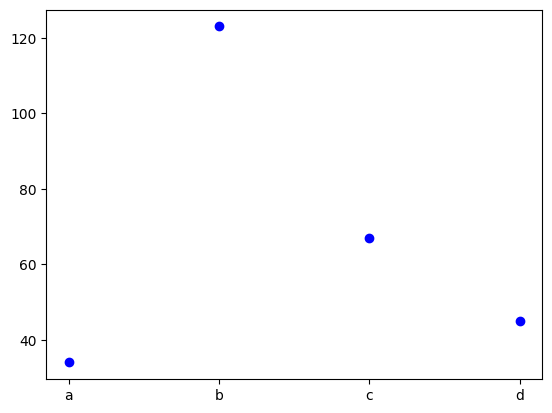

In [ ]:
X = ['a', 'b', 'c', 'd']
Y = [34, 123, 67, 45]

fig, ax = plt.subplots()
ax.plot(X, Y, 'bo')

plt.show()

Здесь 'bo' устанавливает параметр цвета (синий) и параметр маркера (круг). Можно также указать параметр линии (сплошная, пунктирная и т.д.).

'b', 'g', 'r', 'c', 'm', 'y', 'k', 'w' – цвета.

'-', '--', '-.', ':'	- линии.

Параметры записываются в любом порядке и в любом сочетании​. Например, можно указать только маркер и тип линии.

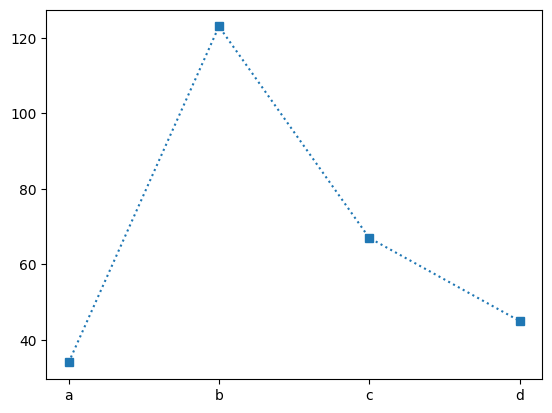

In [ ]:
X = ['a', 'b', 'c', 'd']
Y = [34, 123, 67, 45]

fig, ax = plt.subplots()
ax.plot(X, Y, ':s')

plt.show()

На самом деле, можно использовать функцию plot(), и не создавая отдельный объект Axes, но тогда большинство тонких настроек не будет доступно. Вот пример:

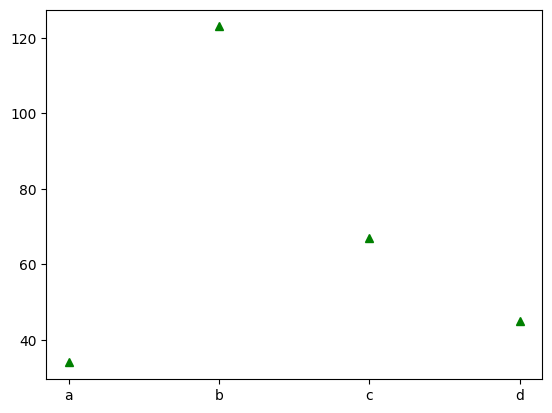

In [ ]:
plt.plot(X, Y, '^g')
plt.show()

При таком использовании plot() объект Figure создаётся автоматически. Если создавать вручную, можно указать figsize – размеры figure в дюймах.

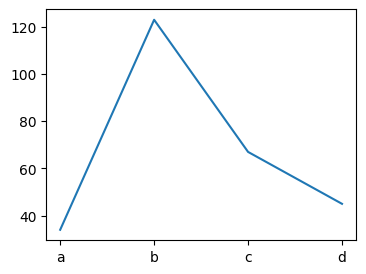

In [ ]:
X = ['a', 'b', 'c', 'd']
Y = [34, 123, 67, 45]

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(X, Y)

plt.show()

Какие еще есть методы в matplotlib?

- ax.scatter(X, Y) - точечный график;
- ax.bar(x, height(y), width, bottom, align) - столбиковый график;
- ax.hist(x, bins) - гистограмма;
- ax.pie(sizes, labels=labels, autopct='%1.1f%%') - пай-чарт (круговая диаграмма).

Можете сами посмотреть, как они устроены и как выглядят.

Какие еще базовые настройки стоит знать, когда строим графики?

- Можно устанавливать xticks (значения по оси х) и yticks;
- Можно устанавливать xlim (предельные значения по оси х) и ylim;
- Можно добавлять легенду ax.legend();
- Можно отображать сетку ax.grid();
- Можно сохранять график с помощью savefig();
- Можно сразу устанавливать весь стиль для графика с помощью plt.style.use(['...']) (посмотреть, какие доступны, можно с помощью plt.style.available).

####LaTeX в matplotlib

Для того чтобы использовать макет формул LaTeX в подписях, заголовках или легендах Matplotlib, вам нужно обернуть математическое выражение в знаки доллара $...$ и обязательно поставить символ r перед началом строки.

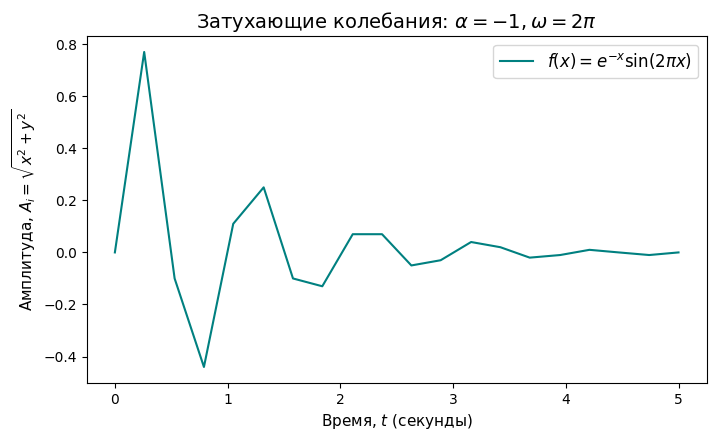

In [63]:
# Симулированные данные затухающих колебаний маятника
x = [0, 0.26, 0.53, 0.79, 1.05, 1.32, 1.58, 1.84, 2.11, 2.37, 2.63, 2.89, 3.16, 3.42, 3.68, 3.95, 4.21, 4.47, 4.74, 5 ]
y = [0, 0.77, -0.1, -0.44, 0.11,  0.25, -0.1, -0.13, 0.07, 0.07, -0.05, -0.03, 0.04, 0.02, -0.02, -0.01, 0.01, 0, -0.01, 0]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, y, color='teal', label=r'$f(x) = e^{-x} \sin(2\pi x)$') # LaTeX в легенде

# LaTeX в заголовке графика
ax.set_title(r'Затухающие колебания: $\alpha = -1, \omega = 2\pi$', fontsize=14)

# LaTeX в подписях к осям
ax.set_xlabel(r'Время, $t$ (секунды)', fontsize=11)
ax.set_ylabel(r'Амплитуда, $A_i = \sqrt{x^2 + y^2}$', fontsize=11)

# LaTeX в легенде
ax.legend(fontsize=12)

plt.show()



3 главных правила работы с LaTeX в Matplotlib:

1. **Всегда используйте r'...':** Если в формуле есть обратный слэш (например, \alpha, \sin, \frac), без буквы r перед строкой код выдаст ошибку или сломает верстку.
2. **Встроенный движок (mathtext):** По умолчанию Matplotlib использует свой собственный встроенный парсер математических выражений. Он поддерживает большинство стандартных формул (\frac, \sqrt, греческие буквы, индексы ^ и _) и не требует установленного на компьютере или в Colab дистрибутива LaTeX.
3. **Обычный текст внутри формулы:** Если внутри математического блока $...$ вам нужно написать обычное слово (например, кириллицей), используйте команду \text{...}, иначе буквы станут наклонными и сольются c формулой.

####Подграфики

Matplotlib позволяет строить много axes внутри одной figure: для этого есть два разных способа. Более гибкий - это использовать метод add_subplot(n), где *n* - трехзначное число. Также можно указать три цифры через запятую. Первая цифра из трех - это номер ряда, вторая - номер строки, а третья - индекс подграфика (matplotlib воспринимает область графика как табличку).

Каждый подграфик можно настраивать как угодно; по умолчанию они поровну делять между собой область figure, но их можно их рисовать как хочется. Они также не обязаны занимать всю область целиком, можно отформатировать каждый подграфик вручную.

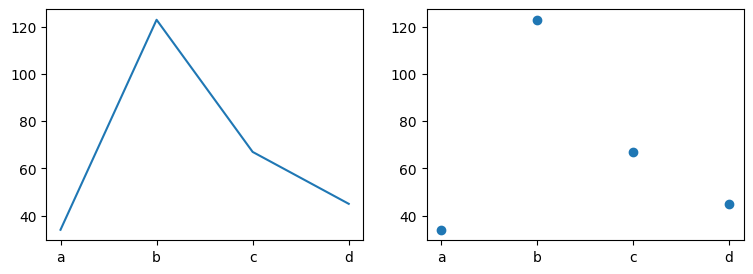

In [ ]:
X = ['a', 'b', 'c', 'd']
Y = [34, 123, 67, 45]

fig = plt.figure(figsize=(9, 3))
ax_1 = fig.add_subplot(1, 2, 1)
ax_2 = fig.add_subplot(1, 2, 2)

ax_1.plot(X, Y)
ax_2.scatter(X, Y)

plt.show()

Более простой (и менее гибкий) способ - это использовать метод subplots().

####Трехмерные графики

В matplotlib есть подбиблиотека, которая позволяет рисовать графики в трехмерном пространстве. Подробно рассматривать не будем, но самый простой пример кода выглядит так:

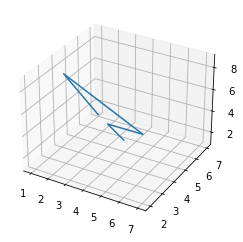

In [ ]:
from mpl_toolkits.mplot3d import axes3d

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
X, Y, Z = [1, 2, 7, 3, 6], [7, 3, 2, 5, 2], [1, 9, 7, 3, 6]
ax.plot(X, Y, Z)
plt.show()

### Seaborn

Seaborn - это библиотека, которая построена на базе matplotlib и очень хорошо с ней взаимодействует. Главная цель Seaborn - это визуализация данных для машинного обучения, поэтому seaborn умеет работать с датафреймами pandas (сейчас это мы смотреть не будем, но кто пойдет на курс ко компьютерной лингвистике в будущем, будет много с ними работать именно в seaborn).

Seaborn тоже, конечно, нужно устанавливать.

    pip install seaborn

Импортируется он обычно как sns:

In [50]:
import seaborn as sns

У него есть возможность автоматически настраивать масштаб графика в зависимости от целей, с которыми вы его создаете:

    sns.set_context('paper', 'notebook', 'talk', 'poster')
    
(Poster сделает крупный график, например). По умолчанию используется notebook.

Самое крутое - это палитры, которые в самом seaborn очень разнообразны, плюс можно собирать их самостоятельно из номеров цветов. Как посмотреть, какие палитры есть в seaborn вообще?

In [ ]:
palette = sns.color_palette("br")  # напечатать какую-нибудь ерунду вместо названия палитры, и в ошибке сиборн послушно вывалит все свои палитры
# увы, этот трюк не прокатит в более новых версиях seaborn :( - но выхлоп ячейки я намеренно сохранила

ValueError: br is not a valid palette name

Дальше уже можно эти названия вбивать и смотреть:

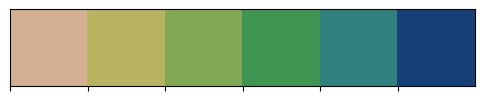

In [51]:
palette = sns.color_palette('gist_earth_r')
sns.palplot(palette)

А вот так можно собрать себе палитру самостоятельно (это можно делать и в чистом matplotlib).

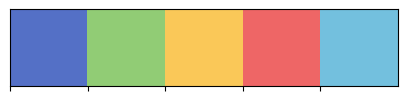

In [52]:
# Кастомная палитра пастельных цветов
colors = ['#5470c6', '#91cc75', '#fac858', '#ee6666', '#73c0de']
sns.palplot(colors)

Что умеет строить seaborn:

- sns.barplot(x=x, y=y, palette=..., ci=None)  # ci - чтобы убрать черную полосу, это стандартное отклонение. В новых версиях эту штуку убрали, можно уже не писать
- sns.pointplot(x=x, y=y, color='lime', alpha=0.8)
- sns.jointplot(x=x, y=y, kind="kde", height=7)
- ...

Поскольку тема построения графиков неисчерпаема, я всячески вас побуждаю самостоятельно копаться в документации и на Стэковерфлоу, чтобы рисовать все более красивые графики. Они здорово помогут вам при защите итогового проекта...

###Plotly

Plotly — библиотека для визуализации данных, состоящая из нескольких частей:

- Front-End на JS
- Back-End на Python (за основу взята библиотека Seaborn)
- Back-End на R

В отличие от matplotlib и seaborn, plotly позволяет строить интерактивные визуализации. Его, конечно, нужно установить:

    pip install plotly
    
Импортируем саму библиотеку и парочку других, которые нам пригодятся.

In [ ]:
import plotly
import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

import numpy as np
import pandas as pd

Попробуем отрисовать обычную параболу.

In [ ]:
def f(x):
    return x ** 2

x = np.arange(0, 5, 0.1)

fig = px.scatter(x=x, y=f(x))
fig.show()

Обратите внимание - при наведении курсора на точки графика будут всплывать подсказки. Это называется экспресс - быстрый способ что-то визуализировать (у matplotlib тоже такой есть).

Настроек, правда, пока маловато. На самом деле plotly точно так же позволяет сперва создавать область графика, а потом добавлять туда какие-то фигуры. В отличие от matplotlib, тут отдельные объекты осей не создаются, хотя мы с ними ещё столкнёмся, когда захотим построить несколько графиков вместе.

In [ ]:
fig = go.Figure()
#Здесь могут быть самые разные штуки
fig.show()

Чтобы добавить что-то на область, нам понадобится метод фигуры add_trace. Что хотим добавить? Наверное, какой-то график. График мы уже рисовали с помощью Scatter в экспрессе, у Объектов есть свой Scatter, давайте глянем, что он делает:

In [ ]:
go.Scatter(x=x, y=f(x))

Scatter({
    'x': array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2, 1.3,
                1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7,
                2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. , 4.1,
                4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9]),
    'y': array([0.000e+00, 1.000e-02, 4.000e-02, 9.000e-02, 1.600e-01, 2.500e-01,
                3.600e-01, 4.900e-01, 6.400e-01, 8.100e-01, 1.000e+00, 1.210e+00,
                1.440e+00, 1.690e+00, 1.960e+00, 2.250e+00, 2.560e+00, 2.890e+00,
                3.240e+00, 3.610e+00, 4.000e+00, 4.410e+00, 4.840e+00, 5.290e+00,
                5.760e+00, 6.250e+00, 6.760e+00, 7.290e+00, 7.840e+00, 8.410e+00,
                9.000e+00, 9.610e+00, 1.024e+01, 1.089e+01, 1.156e+01, 1.225e+01,
                1.296e+01, 1.369e+01, 1.444e+01, 1.521e+01, 1.600e+01, 1.681e+01,
                1.764e+01, 1.849e+01, 1.936e+01, 2.025e+01, 2.116e+01, 2.209e+01,
                2.

А теперь объединим:

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x)))
fig.show()

Как видим, отличия не только в коде, но и в результате — получилась гладкая кривая.

Кроме того, такой способ позволит нам нанести на график столько кривых, сколько мы хотим:

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x)))
fig.add_trace(go.Scatter(x=x, y=x))
fig.show()

Погодите, что это такое? Справа появилась ещё и легенда!

Впрочем, логично, пока график был один, зачем нам легенда?

Но магия Plotly тут не заканчивается. Нажмите на любую из подписей в легенде и соответствующий график исчезнет, а надпись станет более бледной. Вернуть их позволит повторный клик.

*Подписи графиков*

Добавим атрибут name, в который передадим строку с именем графика, которое мы хотим отображать в легенде.

Plotly поддерживает LATEX в подписях (аналогично matplotlib через использование \$\$ с обеих сторон).

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x), name='$$f(x)=x^2$$'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.show()

К сожалению, это имеет свои ограничения, как можно заметить подсказка при наведении на график отображается в «сыром» виде, а не в LATEX.

Победить это можно, если использовать HTML-разметку в подписях. В ней тег sup обозначает superscript. Так же заметьте, что шрифт для LATEX и HTML отличается начертанием.

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x), name='f(x)=x<sup>2</sup>'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.show()

С увеличением длины подписи графика легенда может начать наезжать на график. Можно перенести легенду вниз.

Для этого применим к фигуре метод update_layout, у которого нас интересует атрибут `legend_orientation fig.update_layout(legend_orientation="h")`.

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x),  name='f(x)=x<sup>2</sup>'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.update_layout(legend_orientation="h")
fig.show()

Хорошо, но слишком большая часть рабочего пространства ноутбука не используется. Особенно это заметно сверху — большой отступ сверху до поля графика.

Мы можем задать свои значения отступам с помощью update_layout, у которого есть атрибут margin, принимающий словарь из отступов:

- l — отступ слева
- r — отступ справа
- t — отступ сверху
- b — отступ снизу

Зададим везде отступы поменьше и только внизу оставим большой, под легенду и прочие подписи:

    fig.update_layout(margin=dict(l=0, r=10, t=25, b=65))

update_layout можно применять последовательно несколько раз, либо можно передать все аргументы в одну функцию (мы сделаем именно так).

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x),  name='f(x)=x<sup>2</sup>'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.update_layout(legend_orientation="h",
                  margin=dict(l=0, r=10, t=25, b=65))
fig.show()

Поскольку подписи в легенде короткие, было бы здорово выровнять их по центру.

Для этого можно использовать у update_layout атрибут legend, куда передать словарь с координатами для сдвига (сдвиг может быть и по вертикали, но мы используем только горизонталь).

Сдвиг задаётся в долях от ширины всей фигуры, но важно помнить, что сдвигается левый край легенды. Т.е. если мы укажем 0.5 (50% ширины), то надпись будет на самом деле чуть сдвинута вправо.

Т.к. реальная ширина зависит от особенностей вашего экрана, браузера, шрифтов и т.п., то этот параметр часто приходится подгонять.

Чтобы не шаманить с шириной, можно легенду относительно точки сдвига с помощью аргумента xanchor.

В итоге для легенды мы получим такой словарь:

`legend=dict(x=.5, xanchor="center")`

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x),  name='f(x)=x<sup>2</sup>'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  margin=dict(l=0, r=10, t=25, b=65))
fig.show()

Стоит сразу задать подписи к осям и графику в целом. Для этого нам вновь понадобится update_layout, у которого добавится 3 новых аргумента:

    title="Plot Title",
    xaxis_title="x Axis Title",
    yaxis_title="y Axis Title",

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=f(x),  name='f(x)=x<sup>2</sup>'))
fig.add_trace(go.Scatter(x=x, y=x, name='$$g(x)=x$$'))
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  title="Plot Title",
                  xaxis_title="x Axis Title",
                  yaxis_title="y Axis Title",
                  margin=dict(l=0, r=10, t=25, b=65))
fig.show()

Если же мы хотим изобразить несколько графиков на одном рисунке, для этого нам потребуется создать фигуру с несколькими осями.

Фигура с несколькими графиками создаётся с помощью подмодуля make_subplots.

Необходимо указать количество:

- row — строк
- col — столбцов

А при построении графика передать «координаты» графика в этой «матрице» (сперва строка, потом столбец).

In [ ]:
def h(x):
    return np.sin(x)

def k(x):
    return np.cos(x)

def m(x):
    return np.tan(x)

fig = make_subplots(rows=1, cols=2)

fig.update_yaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='LightPink')
fig.update_xaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='#008000')

fig.add_trace(go.Scatter(x=x, y=h(x),  name='h(x)=sin(x)'), 1, 1)
fig.add_trace(go.Scatter(x=x, y=k(x),  name='k(x)=cos(x)'), 1, 1)
fig.add_trace(go.Scatter(visible='legendonly', x=x, y=m(x),  name='m(x)=tg(x)'), 1, 1)

fig.add_trace(go.Scatter(x=x, y=f(x), mode='lines+markers',  name='f(x)=x<sup>2</sup>'), 1, 2)
fig.add_trace(go.Scatter(x=x, y=x, mode='markers',name='g(x)=x',
                         marker=dict(color='LightSkyBlue', size=20, line=dict(color='MediumPurple', width=3))), 1, 2)
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  hovermode="x",
                  margin=dict(l=0, r=0, t=0, b=0))
fig.update_traces(hoverinfo="all", hovertemplate="Аргумент: %{x}<br>Функция: %{y}")
fig.show()

Заголовки графиков можно задать, при создании фигуры, передав в аргумент subplot_titles кортеж/список с названиями.

Подписи осей под графиками можно поменять с помощью методов фигуры:

    fig.update_xaxes
    fig.update_yaxes

Передавая в них номер строки и колонки (т.е. «координаты изменяемого графика»).

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Plot 1", "Plot 2"))

fig.update_yaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='LightPink', col=2)
fig.update_xaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='#008000', col=2)

fig.add_trace(go.Scatter(x=x, y=h(x),  name='h(x)=sin(x)'), 1, 1)
fig.add_trace(go.Scatter(x=x, y=k(x),  name='k(x)=cos(x)'), 1, 1)
fig.add_trace(go.Scatter(visible='legendonly', x=x, y=m(x),  name='m(x)=tg(x)'), 1, 1)

fig.add_trace(go.Scatter(x=x, y=f(x), mode='lines+markers',  name='f(x)=x<sup>2</sup>'), 1, 2)
fig.add_trace(go.Scatter(x=x, y=x, mode='markers',name='g(x)=x',
                         marker=dict(color='LightSkyBlue', size=20, line=dict(color='MediumPurple', width=3))), 1, 2)
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  hovermode="x",
                  margin=dict(l=0, r=0, t=40, b=0))
fig.update_layout(title="Plot Title")
fig.update_xaxes(title='Ось X графика 1', col=1, row=1)
fig.update_xaxes(title='Ось X графика 2', col=2, row=1)
fig.update_yaxes(title='Ось Y графика 1', col=1, row=1)
fig.update_yaxes(title='Ось Y графика 2', col=2, row=1)
fig.update_traces(hoverinfo="all", hovertemplate="Аргумент: %{x}<br>Функция: %{y}")
fig.show()

И конечно, если необходимо сделать так, чтобы один график был больше, а другой меньше, то для этого используется аргументы

- column_widths — задаёт отношения ширины графиков (в одной строке)
- row_heights — задаёт отношения высот графиков (в одном столбце)

Каждый из этих параметров принимает список чисел, которых должно быть столько, сколько графиков в строке/столбце. Отношения чисел задают отношения ширин или высот.

Рассмотрим на примере ширин. Сделаем левый график вдвое шире правого, т.е. зададим соотношение 2:1.

In [ ]:
fig = make_subplots(rows=1, cols=2, column_widths=[2, 1])

fig.update_yaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='LightPink', col=2)
fig.update_xaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='#008000', col=2)

fig.add_trace(go.Scatter(x=x, y=h(x),  name='h(x)=sin(x)'), 1, 1)
fig.add_trace(go.Scatter(x=x, y=k(x),  name='k(x)=cos(x)'), 1, 1)
fig.add_trace(go.Scatter(visible='legendonly', x=x, y=m(x),  name='m(x)=tg(x)'), 1, 1)

fig.add_trace(go.Scatter(x=x, y=f(x), mode='lines+markers',  name='f(x)=x<sup>2</sup>'), 1, 2)
fig.add_trace(go.Scatter(x=x, y=x, mode='markers',name='g(x)=x',
                         marker=dict(color='LightSkyBlue', size=20, line=dict(color='MediumPurple', width=3))), 1, 2)
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  hovermode="x",
                  margin=dict(l=0, r=0, t=0, b=0))
fig.update_traces(hoverinfo="all", hovertemplate="Аргумент: %{x}<br>Функция: %{y}")
fig.show()

А что если мы хотим выделить одному из графиков больше места, чем другим, например, 2 строки или наоборот, 2 столбца?

В matplotlib мы использовали бы несколько фигур, либо оси с заданными размерами, здесь у нас есть другой инструмент. Мы можем сказать каким-то осям объединиться вдоль колонок или вдоль строк.

Для этого нам потребуется написать спецификацию на фигуру (для начала очень простую).

Спецификация — это список (если точнее, то даже матрица из списков), каждый объект внутри которого — словарь, описывающий одни из осей.

Если каких-то осей нет (например, если их место занимают растянувшиеся соседи, то вместо словаря передаётся None.

Давайте сделаем матрицу 2х2 и объединим вместе левые графики, получив одни высокие вертикальные оси. Для этого первому графику передадим атрибут «rowspan» равный 2, а его нижнего соседа уничтожим (None):

    specs=[

     [{"rowspan": 2}, {}],

     [None, {}]

    ]

In [ ]:
fig = make_subplots(rows=2, cols=2,
                    specs=[[{"rowspan": 2}, {}], [None, {}]])


fig.update_yaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='LightPink', col=2)
fig.update_xaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='#008000', col=2)

fig.add_trace(go.Scatter(x=x, y=h(x),  name='h(x)=sin(x)'), 2, 2)
fig.add_trace(go.Scatter(x=x, y=k(x),  name='k(x)=cos(x)'), 2, 2)
fig.add_trace(go.Scatter(x=x, y=m(x),  name='m(x)=tg(x)'), 1, 1)

fig.add_trace(go.Scatter(x=x, y=f(x), mode='lines+markers',  name='f(x)=x<sup>2</sup>'), 1, 2)
fig.add_trace(go.Scatter(x=x, y=x, mode='markers',name='g(x)=x',
                         marker=dict(color='LightSkyBlue', size=20, line=dict(color='MediumPurple', width=3))), 1, 2)
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  hovermode="x",
                  margin=dict(l=0, r=0, t=0, b=0))
fig.update_traces(hoverinfo="all", hovertemplate="Аргумент: %{x}<br>Функция: %{y}")
fig.show()

Как можно было заметить, графики plotly занимают всю доступную ширину, а нам может хотеться задавать ее. Давайте это сделаем:

In [ ]:
fig = make_subplots(rows=2, cols=2,
                    specs=[[{"colspan": 2}, None], [{}, {}]])


fig.update_yaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='LightPink', col=2)
fig.update_xaxes(range=[-0.5, 1.5], zeroline=True, zerolinewidth=2, zerolinecolor='#008000', col=2)

fig.add_trace(go.Scatter(x=x, y=h(x),  name='h(x)=sin(x)'), 2, 2)
fig.add_trace(go.Scatter(x=x, y=k(x),  name='k(x)=cos(x)'), 2, 2)
fig.add_trace(go.Scatter(x=x, y=m(x),  name='m(x)=tg(x)'), 1, 1)

fig.add_trace(go.Scatter(x=x, y=f(x), mode='lines+markers',  name='f(x)=x<sup>2</sup>'), 2, 1)
fig.add_trace(go.Scatter(x=x, y=x, mode='markers',name='g(x)=x',
                         marker=dict(color='LightSkyBlue', size=20, line=dict(color='MediumPurple', width=3))), 2, 1)
fig.update_layout(legend_orientation="h",
                  legend=dict(x=.5, xanchor="center"),
                  hovermode="x",
                  margin=dict(l=0, r=0, t=0, b=0),
                  height=1000,
                  width=600)
fig.update_traces(hoverinfo="all", hovertemplate="Аргумент: %{x}<br>Функция: %{y}")
fig.show()

Остальные клевые штуки по plotly вы можете посмотреть и потыкать в оригинальной [статье с хабра](https://habr.com/ru/articles/502958/), часть которой я тут и пересказываю. :)